# Лабораторная работа №2. Наивный Байес, target encoding, логистическая регрессия

**ФИО:** Елисеев Андрей Дмитриевич  **Группа:** 24213

**1. Задание:** Импортируйте библиотеки и задайте названия 22 признаков Mushroom.  
**Подсказка:** Нужны pandas, numpy, matplotlib, sklearn; число категорий у признаков различается.

In [331]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

TARGET="class"
FEATURE_NAMES=[
    "cap-shape",
    "cap-surface",
    "cap-color",
    "bruises",
    "odor",
    "gill-attachment",
    "gill-spacing",
    "gill-size",
    "gill-color",
    "stalk-shape",
    "stalk-root",
    "stalk-surface-above-ring",
    "stalk-surface-below-ring",
    "stalk-color-above-ring",
    "stalk-color-below-ring",
    "veil-type",
    "veil-color",
    "ring-number",
    "ring-type",
    "spore-print-color",
    "population",
    "habitat",
]
RANDOM_STATE=42

**2. Задание:** Загрузите Mushroom из UCI в DataFrame, выведите форму и баланс классов.  
**Подсказка:** У файла нет заголовка; символ «?» — категория отсутствующего значения, а не NaN.

In [399]:
df = pd.read_csv("./mushrooms.csv", header=None)
df.columns = [TARGET] + FEATURE_NAMES

print("shape:", df.shape)
display(df[TARGET].value_counts(normalize=True).to_frame())
display(df.head(5))

# 22 признака, значения закодированы буквами.
# 2 класса - edible и poisonous. 
# Небольшой перевес в сторону edible.

shape: (8124, 23)


,proportion
class,
e,0.517971
p,0.482029


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


**3. Задание:** Найдите число категорий и долю «?» для каждого признака.  
**Подсказка:** Используйте nunique() и eq("?").sum(); проверьте, есть ли константные признаки.

In [333]:
audit = pd.DataFrame({
    "n_unique": df[FEATURE_NAMES].nunique(), 
    "question_marks": df[FEATURE_NAMES].eq("?").sum()
})
display(audit)

# Есть неизвестные значения только у признака stalk-root.
# Константный признак veil-type.

,n_unique,question_marks
cap-shape,6,0
cap-surface,4,0
cap-color,10,0
bruises,2,0
odor,9,0
gill-attachment,2,0
gill-spacing,2,0
gill-size,2,0
gill-color,12,0
stalk-shape,2,0


**4. Задание:** Вычислите частоты всех категорий по классам через groupby.  
**Подсказка:** Для каждого X_j нужна таблица категории × {e, p}, сумма элементов равна размеру df.

In [334]:
freq_tables = {feature: df.groupby(feature)[TARGET].value_counts().unstack(fill_value=0) for feature in FEATURE_NAMES}

display(freq_tables["odor"])
display(freq_tables["stalk-root"])

# Классы хорошо отделяются по odor.

class,e,p
odor,,
a,400,0
c,0,192
f,0,2160
l,400,0
m,0,36
n,3408,120
p,0,256
s,0,576
y,0,576


class,e,p
stalk-root,,
?,720,1760
b,1920,1856
c,512,44
e,864,256
r,192,0


**5. Задание:** Постройте графики распределений по классам для 22 признаков.  
**Подсказка:** Для каждой таблицы частот используйте plot.bar(stacked=True), объедините рисунки в сетку.

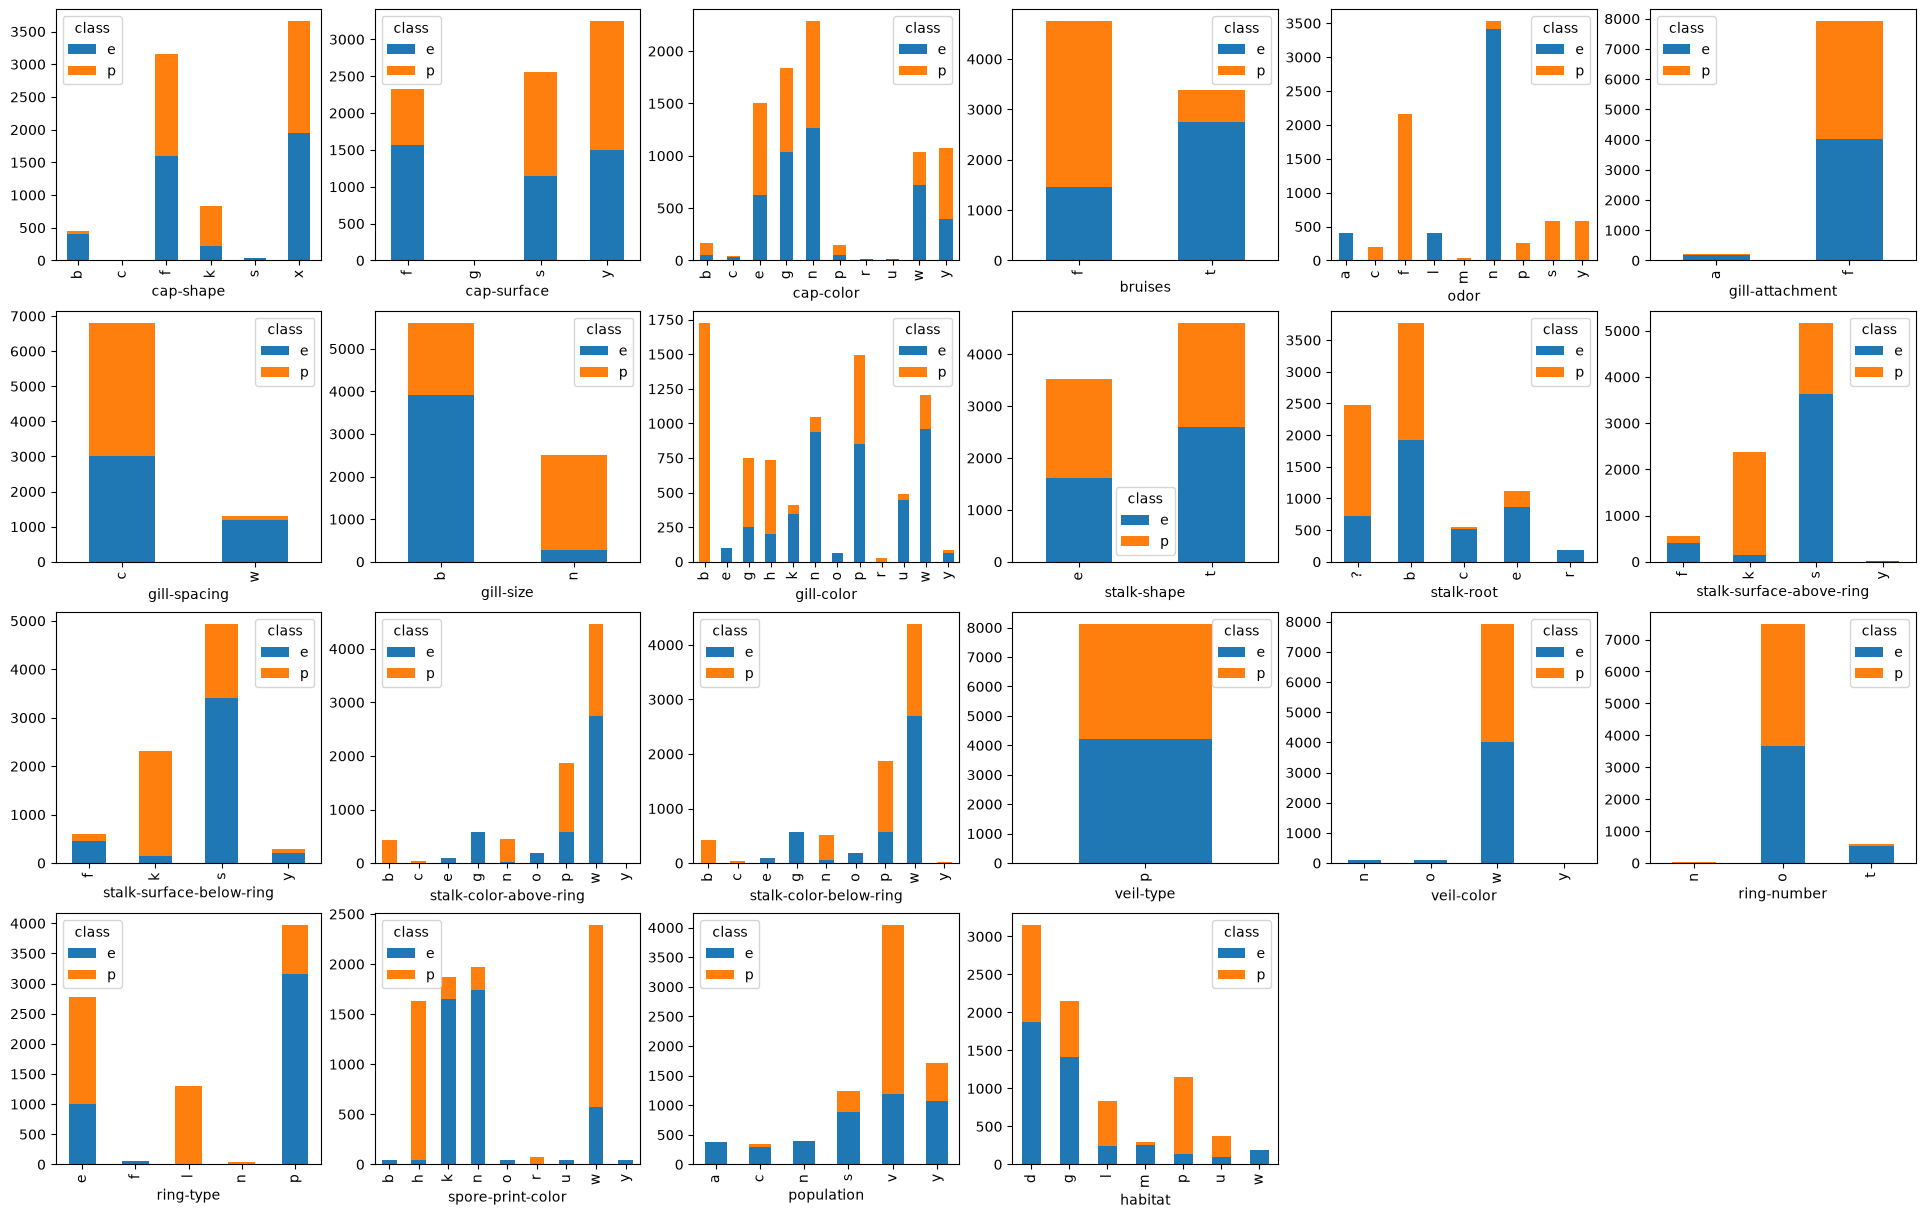

In [ ]:
fig, axes = plt.subplots(nrows=4, ncols=6, figsize=(24, 15))
for ax, table in zip(axes.flat, freq_tables.values()):
    table.plot.bar(ax=ax, stacked=True)
for ax in axes.flat[len(freq_tables):]:
    ax.remove()

# К Р А С О Т А

**6. Задание:** Разделите данные на train/test (75/25) со стратификацией.  
**Подсказка:** random_state=42, stratify=y; впредь связи признаков с классом считайте только на train.

In [336]:
X = df[FEATURE_NAMES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

display(y_train.value_counts(normalize=True).to_frame().style.set_caption("Train"))
display(y_test.value_counts(normalize=True).to_frame().style.set_caption("Test"))

# В тренировочном немного больше доля edible, чем в тестовом.

,proportion
class,
e,0.519941
p,0.480059


,proportion
class,
e,0.512063
p,0.487937


**7. Задание:** Реализуйте частотный классификатор по одному признаку и ранжируйте все признаки.  
**Подсказка:** Для каждой категории предсказывайте класс с максимальной частотой в train; неизвестные → мажоритарный класс.

In [374]:
def single_feature_predict(X_fit, y_fit, X_query, feature):
    freq_table = pd.concat([y_train, X_train[feature]], axis=1).groupby(feature).value_counts().unstack(fill_value=0)
    class_map = pd.DataFrame({"prediction": freq_table[["e", "p"]].idxmax(axis=1)})
    class_map.loc["?", "prediction"] = y_train.value_counts().idxmax()
    X_merged = pd.merge(X_query, class_map, how="left", left_on=feature, right_index=True)
    return X_merged["prediction"]

def make_row(feature):
    y_pred_train = single_feature_predict(X_train, y_train, X_train, feature)
    y_pred_test = single_feature_predict(X_train, y_train, X_test, feature)
    train_errors = y_train.ne(y_pred_train).sum()
    test_errors = y_test.ne(y_pred_test).sum()
    train_acc = 1 - train_errors / y_train.shape[0]
    test_acc = 1 - test_errors / y_test.shape[0]
    return feature, train_errors, train_acc, test_acc

freq_rows = sorted([make_row(feature) for feature in FEATURE_NAMES], key=lambda row: row[3], reverse=True)
pd.DataFrame(freq_rows, columns=["feature", "train_errors", "train_acc", "test_acc"]).head(10)

# Самый информативный признак - odor.

,feature,train_errors,train_acc,test_acc
0,odor,90,0.985229,0.985229
1,spore-print-color,805,0.867881,0.868538
2,gill-color,1189,0.804858,0.805515
3,ring-type,1377,0.774003,0.779911
4,stalk-surface-above-ring,1351,0.778270,0.763171
5,stalk-surface-below-ring,1409,0.768751,0.758247
6,gill-size,1467,0.759232,0.747415
7,bruises,1540,0.747251,0.734121
8,population,1689,0.722797,0.718858
9,stalk-color-above-ring,1726,0.716724,0.715411


**8. Задание:** Проверьте правило минимальных ошибок и визуализируйте качество 22 одиночных признаков.  
**Подсказка:** Минимум ошибок на train равен сумме min(n_e, n_p) по категориям данного признака.

<Axes: ylabel='feature'>

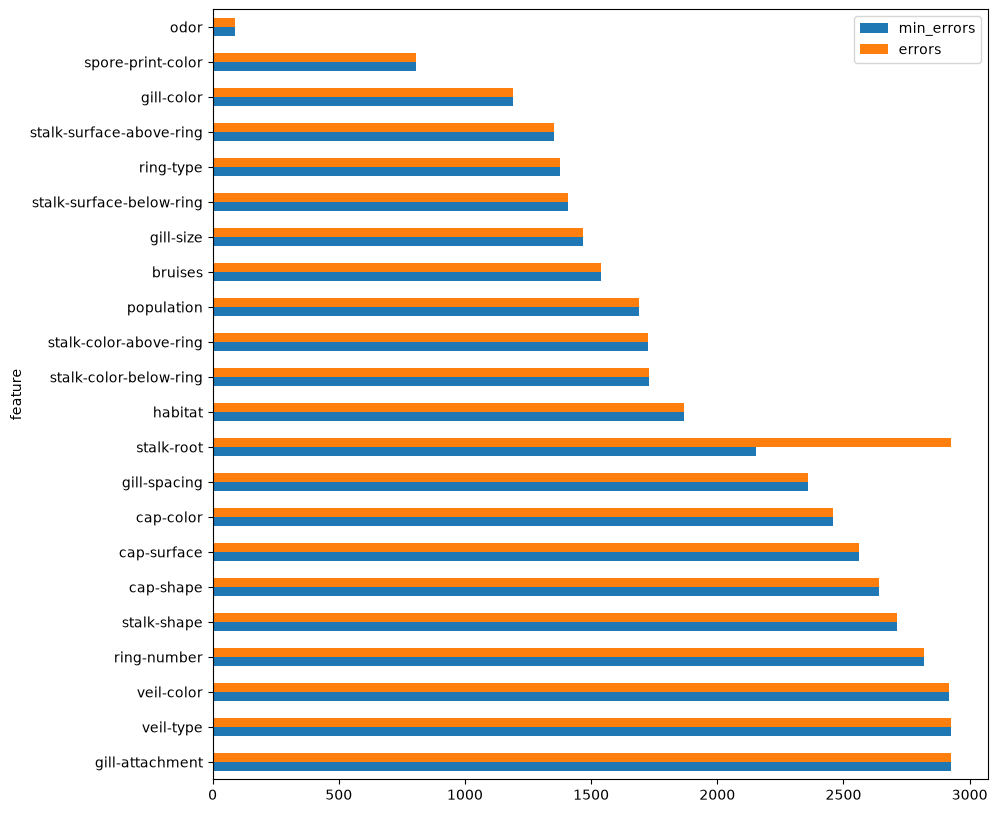

In [398]:
comparison_errors = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "min_errors": [pd.concat([y_train, X_train[feature]], axis=1).groupby(feature).value_counts().unstack(fill_value=0).min(axis=1).sum() for feature in FEATURE_NAMES],
    "errors": [y_train.ne(single_feature_predict(X_train, y_train, X_train, feature)).sum() for feature in FEATURE_NAMES]
}).set_index("feature").sort_values("min_errors", ascending=False)

comparison_errors.plot.barh(figsize=(10, 10))

**9. Задание:** Закодируйте категориальные признаки целыми числами и обучите CategoricalNB.  
**Подсказка:** У каждого столбца свой набор кодов 0,1,...; min_categories задаёт размеры алфавитов.

In [339]:
# TODO: категории для каждого признака, X_train_code, X_test_code
# TODO: nb_sklearn = CategoricalNB(...).fit(...)
# TODO: train/test accuracy и матрица ошибок

**10. Задание:** Самостоятельно реализуйте наивный Байес с аддитивным сглаживанием.  
**Подсказка:** P(x_j=v|k)=(n_jvk+alpha)/(n_k+alpha*M_j); суммируйте логарифмы, включая log P(k).

In [340]:
def manual_nb_fit(X, y, n_categories, alpha=1.0):
    # TODO: вероятности классов и категорий в логарифмах
    pass

def manual_nb_predict(X, params):
    # TODO: argmax сумм логарифмов по классам
    pass

**11. Задание:** Сравните собственный Байес с библиотечным и исследуйте три значения alpha.  
**Подсказка:** Одинаковые данные и alpha должны дать одинаковые метки; используйте alpha = 0.1, 1, 10.

In [341]:
# TODO: pred_manual, доля совпадения с nb_test_pred
# TODO: smoothing_results с train/test accuracy для alpha=0.1,1,10

**12. Задание:** Преобразуйте категории в logit сглаженной вероятности класса p.  
**Подсказка:** Оцените P(p|x_j=v) только по train; для новых категорий используйте общую вероятность p из train.

In [342]:
def fit_logit_encoder(X_fit, y_fit, alpha=1.0):
    # TODO: словари category -> logit(p) для каждого признака
    pass

def transform_logit_encoder(X_query, fitted):
    # TODO: примените словари, y_query не использовать
    pass

**13. Задание:** Обучите логистическую регрессию на 22 logit-признаках и сравните методы.  
**Подсказка:** fit кодировщика только на train; одинаковая test-выборка для всех моделей.

In [343]:
# TODO: encoder_logit, X_train_logit, X_test_logit
# TODO: logreg; comparison = DataFrame по четырём моделям

**14. Задание:** Удалите признак odor, переобучите Байеса и сравните качество.  
**Подсказка:** Удалите соответствующий индекс из закодированных массивов и списка размеров категорий.

In [344]:
# TODO: ablation_results (all, without_odor) с train/test accuracy

**15. Задание:** Сформулируйте краткий вывод по четырём экспериментам.  
**Подсказка:** Укажите лучший признак, совпадение двух реализаций Байеса, влияние alpha и исключения odor.

In [345]:
# TODO: выведите / запишите 3–4 вывода с числами ваших экспериментов